<a href="https://colab.research.google.com/github/CarlosFranciscoM-Urzua/EJERCICIOS_PLN_COLAB/blob/main/Practica_Sentimientos_Unidad4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Práctica guiada: análisis de sentimiento**
Unidad 4 · Procesamiento del Lenguaje Natural
Entorno: Google Colab | Python | Duración sugerida: 90–120 minutos

Montoya Urzúa Carlos Francisco


##1.	Objetivo
Desarrollar un clasificador supervisado de comentarios en español que identifique sentimientos positivos, negativos y neutrales. Se utilizarán TF-IDF y regresión logística. El estudiante aprenderá a preparar ejemplos, entrenar, evaluar y probar un modelo.
##2.	Antes de comenzar
Abra Google Colab en su navegador, cree un cuaderno nuevo y guárdelo como
Practica_Sentimientos_Unidad4. Cada fragmento de código siguiente debe copiarse en una celda nueva y ejecutarse con Shift + Enter. El entorno suele incluir las bibliotecas necesarias.
##3.	Importar las bibliotecas


In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

Explicación: pandas organiza datos; train_test_split separa los ejemplos; TfidfVectorizer transforma texto en valores numéricos; LogisticRegression clasifica; Pipeline conecta el procesamiento y el modelo; las métricas ayudan a evaluar.

##4.	Crear un conjunto de comentarios etiquetados
Escriba estos ejemplos. La segunda columna es la categoría correcta asignada manualmente.


In [3]:
datos = [
    ("Me encantó la aplicación", "positivo"),
    ("El servicio fue excelente", "positivo"),
    ("La interfaz es muy cómoda", "positivo"),
    ("Funciona rápido y bien", "positivo"),
    ("Estoy satisfecho con el resultado", "positivo"),
    ("La atención fue amable", "positivo"),
    ("La aplicación falla mucho", "negativo"),
    ("El servicio fue pésimo", "negativo"),
    ("Es muy lenta y confusa", "negativo"),
    ("No recomiendo esta herramienta", "negativo"),
    ("Estoy decepcionado con el resultado", "negativo"),
    ("La atención fue terrible", "negativo"),
    ("La aplicación se actualizó ayer", "neutral"),
    ("El sistema tiene tres módulos", "neutral"),
    ("La reunión inicia a las nueve", "neutral"),
    ("El archivo contiene veinte registros", "neutral"),
    ("El curso comienza el lunes", "neutral"),
    ("La plataforma está disponible en línea", "neutral")
]
df = pd.DataFrame(
    datos,
    columns=["comentario", "sentimiento"]
)

print(df.head())
print(df["sentimiento"].value_counts())


                          comentario sentimiento
0           Me encantó la aplicación    positivo
1          El servicio fue excelente    positivo
2          La interfaz es muy cómoda    positivo
3             Funciona rápido y bien    positivo
4  Estoy satisfecho con el resultado    positivo
sentimiento
positivo    6
negativo    6
neutral     6
Name: count, dtype: int64


Resultado esperado: seis ejemplos positivos, seis negativos y seis neutrales. El conjunto es pequeño y solo sirve para aprender el procedimiento.

##5.	Separar datos de entrenamiento y prueba

El modelo aprende con una parte de los ejemplos; el resto se reserva para evaluar predicciones con textos no utilizados en el entrenamiento. stratify mantiene el equilibrio de las categorías.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["comentario"],
    df["sentimiento"],
    test_size=0.33,
    random_state=42,
    stratify=df["sentimiento"]
)

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))

Entrenamiento: 12
Prueba: 6


Resultado esperado: 12 comentarios para entrenamiento y 6 para prueba.
## 6.	Convertir palabras a números y entrenar
TF-IDF asigna pesos a las palabras según su frecuencia y relevancia. Con ngram_range=(1,2) se consideran palabras individuales y parejas de palabras (por ejemplo, “no recomiendo”). La regresión logística aprende a distinguir las tres clases.


In [5]:
modelo = Pipeline([
    ("tfidf",
    TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2))
    ),
    ("clasificador",
    LogisticRegression(max_iter=1000))
])

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


## 7.	Evaluar el clasificador

In [6]:
predicciones = modelo.predict(X_test)
print(classification_report(
    y_test, predicciones,
    zero_division=0))

print("Matriz de confusión:")

print(confusion_matrix(
    y_test,
    predicciones,
    labels=["negativo", "neutral", "positivo"]))


              precision    recall  f1-score   support

    negativo       0.00      0.00      0.00       2.0
     neutral       0.00      0.00      0.00       2.0
    positivo       0.00      0.00      0.00       2.0

    accuracy                           0.00       6.0
   macro avg       0.00      0.00      0.00       6.0
weighted avg       0.00      0.00      0.00       6.0

Matriz de confusión:
[[0 1 1]
 [1 0 1]
 [2 0 0]]


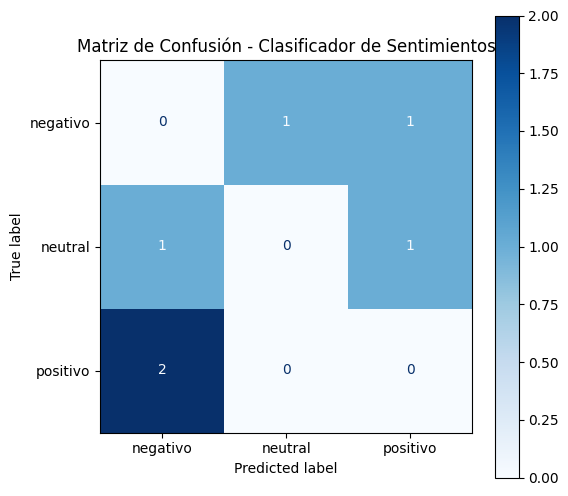

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Definir las etiquetas de las clases
clases = ["negativo", "neutral", "positivo"]

# Calcular la matriz de confusión
cm = confusion_matrix(y_test, predicciones, labels=clases)

# Crear la visualización gráfica
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases)

# Dibujar la matriz de confusión
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Matriz de Confusión - Clasificador de Sentimientos")
plt.grid(False)
plt.show()

Interpretación: precision expresa qué proporción de las predicciones de una clase fue correcta; recall expresa qué proporción de los casos reales se detectó; F1 combina ambas. En la matriz de confusión, los valores de la diagonal corresponden a aciertos. Con solo seis ejemplos de prueba, las métricas no son estables.

## 8.	Clasificar comentarios nuevos

In [8]:
nuevos = [
    "Me gustó mucho la plataforma",
    "No funciona y es muy mala",
    "El sistema se instaló el martes",
    "La cámara es buena, pero la batería es mala"
]
resultados = modelo.predict(nuevos)

for texto, etiqueta in zip(nuevos, resultados):
    print(f"{texto} --> {etiqueta}")


Me gustó mucho la plataforma --> negativo
No funciona y es muy mala --> negativo
El sistema se instaló el martes --> neutral
La cámara es buena, pero la batería es mala --> negativo


Observe las etiquetas que devuelve su ejecución. No hay un resultado garantizado para cada ejemplo: son predicciones de un modelo entrenado con muy pocos datos. El último comentario expresa opiniones mixtas, que no están representadas como categoría independiente.

## 9.	Consultar probabilidades estimadas

In [9]:
texto = ["La aplicación es excelente"]

probabilidades = modelo.predict_proba(texto)[0]

for clase, prob in zip(modelo.classes_, probabilidades):
    print(f"{clase}: {prob:.2%}")

negativo: 34.69%
neutral: 30.01%
positivo: 35.30%


Las probabilidades indican la distribución de confianza estimada por el modelo; no deben interpretarse como certeza absoluta.
## 10.	Experimentar con negación, ironía y contexto
Agregue estas frases a la lista de comentarios nuevos y repita el paso 8: “No está nada mal”, “¡Qué maravilla!, volvió a fallar”, “Me gusta el diseño, pero no el precio”. Registre las predicciones y explique por qué son casos difíciles.


In [15]:
nuevos = [
    "Me gustó mucho la plataforma",
    "No funciona y es muy mala",
    "El sistema se instaló el martes",
    "La cámara es buena, pero la batería es mala",
    "No está nada mal",
    "¡Qué maravilla!, volvió a fallar",
    "Me gusta el diseño, pero no el precio"
]
resultados = modelo.predict(nuevos)

for texto, etiqueta in zip(nuevos, resultados):
    print(f"{texto:<50} --> {etiqueta}")


Me gustó mucho la plataforma                       --> negativo
No funciona y es muy mala                          --> negativo
El sistema se instaló el martes                    --> neutral
La cámara es buena, pero la batería es mala        --> negativo
No está nada mal                                   --> neutral
¡Qué maravilla!, volvió a fallar                   --> neutral
Me gusta el diseño, pero no el precio              --> positivo


Muchas de estas son difíciles por las propias características del castellano, como la negación de un comentario ya negativo para crear un positivo o el uso de sarcásno.

## 11.	Actividades para los estudiantes

### Actividad A: incorpore 12 comentarios originales (cuatro de cada categoría), cree de nuevo el DataFrame y entrene otra vez.

In [17]:
datos += [
    ("La nueva versión es increíblemente rápida", "positivo"),
    ("Me resolvió el problema al instante, excelente servicio", "positivo"),
    ("El diseño visual es hermoso y muy moderno", "positivo"),
    ("Altamente recomendado para agilizar las tareas diarias", "positivo"),

    ("No carga las imágenes y se cierra sola", "negativo"),
    ("Es una pérdida de tiempo, no funciona nada bien", "negativo"),
    ("El soporte técnico nunca responde mis mensajes", "negativo"),
    ("Tiene demasiada publicidad molesta e inservible", "negativo"),

    ("El software requiere conexión a internet para funcionar", "neutral"),
    ("La suscripción mensual se renueva de forma automática", "neutral"),
    ("El manual de usuario consta de tres páginas", "neutral"),
    ("Recibí una notificación sobre el mantenimiento programado", "neutral")
]

df = pd.DataFrame(
    datos,
    columns=["comentario", "sentimiento"]
)

X_train, X_test, y_train, y_test = train_test_split(
    df["comentario"],
    df["sentimiento"],
    test_size=0.33,
    random_state=42,
    stratify=df["sentimiento"]
)

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))

# ENTRENAMIENTO DEL MODELO
modelo = Pipeline([
    ("tfidf",
    TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2))
    ),
    ("clasificador",
    LogisticRegression(max_iter=1000))
])

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente con los nuevos datos")

Entrenamiento: 20
Prueba: 10
Modelo entrenado correctamente con los nuevos datos


###Actividad B: compare ngram_range=(1,1) con (1,2).

Caso ngram_range=(1,1)

In [19]:
modelo_ngram_1_1 = Pipeline([
    ("tfidf",
    TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 1))
    ),
    ("clasificador",
    LogisticRegression(max_iter=1000))
])

modelo_ngram_1_1.fit(X_train, y_train)

predicciones = modelo_ngram_1_1.predict(X_test)
print(classification_report(
    y_test, predicciones,
    zero_division=0))

print("Matriz de confusión:")

print(confusion_matrix(
    y_test,
    predicciones,
    labels=["negativo", "neutral", "positivo"]))


              precision    recall  f1-score   support

    negativo       0.40      0.67      0.50         3
     neutral       0.50      0.67      0.57         3
    positivo       0.00      0.00      0.00         4

    accuracy                           0.40        10
   macro avg       0.30      0.44      0.36        10
weighted avg       0.27      0.40      0.32        10

Matriz de confusión:
[[2 1 0]
 [0 2 1]
 [3 1 0]]


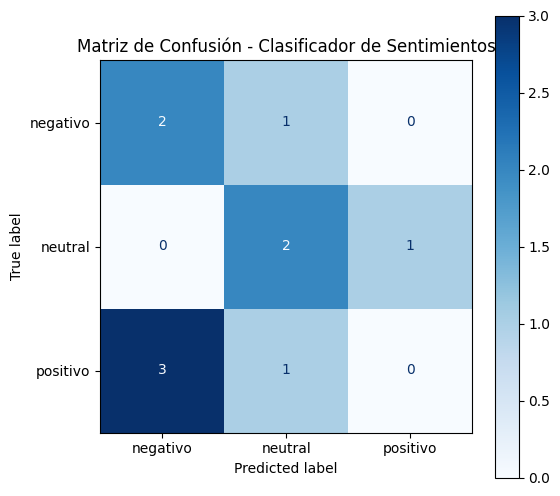

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Definir las etiquetas de las clases
clases = ["negativo", "neutral", "positivo"]

# Calcular la matriz de confusión
cm = confusion_matrix(y_test, predicciones, labels=clases)

# Crear la visualización gráfica
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases)

# Dibujar la matriz de confusión
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Matriz de Confusión - Clasificador de Sentimientos")
plt.grid(False)
plt.show()

Caso ngram_range=(1,2)

In [21]:
modelo_ngram_1_2 = Pipeline([
    ("tfidf",
    TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2))
    ),
    ("clasificador",
    LogisticRegression(max_iter=1000))
])

modelo_ngram_1_2.fit(X_train, y_train)

predicciones = modelo_ngram_1_2.predict(X_test)
print(classification_report(
    y_test, predicciones,
    zero_division=0))

print("Matriz de confusión:")

print(confusion_matrix(
    y_test,
    predicciones,
    labels=["negativo", "neutral", "positivo"]))


              precision    recall  f1-score   support

    negativo       0.25      0.33      0.29         3
     neutral       0.40      0.67      0.50         3
    positivo       0.00      0.00      0.00         4

    accuracy                           0.30        10
   macro avg       0.22      0.33      0.26        10
weighted avg       0.20      0.30      0.24        10

Matriz de confusión:
[[1 2 0]
 [0 2 1]
 [3 1 0]]


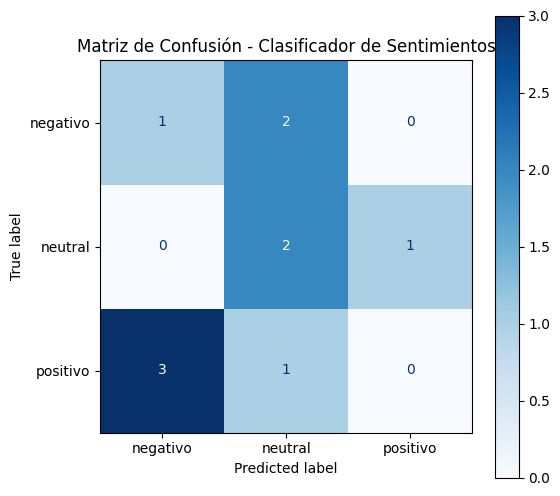

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Definir las etiquetas de las clases
clases = ["negativo", "neutral", "positivo"]

# Calcular la matriz de confusión
cm = confusion_matrix(y_test, predicciones, labels=clases)

# Crear la visualización gráfica
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases)

# Dibujar la matriz de confusión
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Matriz de Confusión - Clasificador de Sentimientos")
plt.grid(False)
plt.show()

Según las matrices de confusión y las métricas usadas, el modelo con ngram_range=(1,1) resulta dar predicciones más precisas.

###Actividad C: describa dos errores de clasificación y proponga mejoras.

**Incapacidad para procesar opiniones mixtas o contrastes.**

*Ejemplo:* El comentario *"La cámara es buena, pero la batería es mala"* fue clasificado como negativo cuando debería ser neutral. Al tener un vocabulario limitado y no ponderar la estructura de la oración (como el conector adversativo "pero"), el modelo simplifica la predicción hacia una sola categoría.

**Confusión ante la ironía o sarcasmo.**

*Ejemplo:* La frase *"¡Qué maravilla!, volvió a fallar"* contiene la palabra fuertemente positiva "maravilla", lo que confunde al clasificador simple y lo lleva a predecir **neutral** o positivo, ignorando el contexto negativo real de la falla.

#### Mejoras Propuestas:
*   **Ampliación y Balanceo del Dataset.** El modelo actual se entrena con muy pocos datos. Agregar cientos de ejemplos que contengan conectores de contraste ("pero", "aunque", "sin embargo") e ironías explícitas ayudará a que el vectorizador capture mejor el peso de estas combinaciones de palabras.
*   **Uso de Modelos Basados en Aprendizaje Profundo o Transformers.** Sustituir la regresión logística y TF-IDF por modelos preentrenados de lenguaje (como **BETO** o **mBERT**). Estos modelos utilizan mecanismos de atención que interpretan el contexto completo y las relaciones semánticas complejas entre las palabras, permitiendo detectar de forma mucho más precisa el sarcasmo y los matices en oraciones de opinión mixta.

### Actividad D: redacte una conclusión de 8 a 10 líneas.

Esta práctica me permitió entender como simplificar grandes volumenes de comentarios a los sentimientos que expresan, lo que permite procesar grandes cantidades de críticas y extraer la opinión general de los usuarios.

Además fue interesante como utilizar el algoritmo FT-IDF para clasificar documentos según sus sentimientos expresados. Aún cuando este no es el modelo más preciso, sigue siendo de gran utilidad.

Esta práctica me sirvió para repasar conceptos de Aprendizaje Automático, como las métricas para modelos de IA, y otros algoritmos de PNL vistos en unidades pasadas.

Por último, cabe destacar que enfrentarse a los matices del idioma español, como la negación o las opiniones encontradas, nos obligaría a transicionar hacia arquitecturas de deep learning más complejas. Esto muestra que la analítica de texto requiere un refinamiento constante y un diseño iterativo para mejorar la precisión y robustez en entornos reales.

## 12.	Evidencias de aprendizaje y evaluación
Entregue el cuaderno .ipynb con todas las celdas ejecutadas, los resultados de las métricas, las predicciones de comentarios nuevos y las respuestas. Rúbrica sugerida: código funcional 30 %, entrenamiento y evaluación 30 %, experimentos y análisis de errores 25 %, conclusiones y presentación 15 %.
## 13.	Conclusión
Esta práctica muestra cómo convertir comentarios en características numéricas y entrenar un clasificador supervisado. Para un uso real se requieren más datos representativos, validación rigurosa y revisión de sesgos. Los modelos también pueden fallar ante sarcasmo, negaciones y opiniones mixtas.
